In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tabulate import tabulate

DATA_PATH = r"D:\ai-lab\DS\corpus.json"

with open(DATA_PATH, encoding="utf-8") as f:
    df = pd.DataFrame(json.load(f))

df["text"] = (df["title"].fillna("") + " " + df["abstract"].fillna("")).str.strip()

print(df.shape)
print()

counts = df["label"].value_counts().sort_index()
share = df["label"].value_counts(normalize=True).sort_index()

subjects = {
    1: "پزشکی و علوم بالینی",
    2: "کشاورزی و منابع طبیعی",
    3: "فنی و مهندسی",
    4: "علوم پایه",
    5: "علوم انسانی و اجتماعی",
    6: "هنر و معماری",
    7: "دامپزشکی",
}

summary = pd.DataFrame({
    "label": counts.index,
    "count": counts.values,
    "percent": (share.values * 100).round(1),
})
summary["subject"] = summary["label"].map(subjects)
summary = summary.set_index("label")

print(summary)

TARGET_LABEL = (share - 0.10).abs().idxmin()
df["is_target"] = df["label"] == TARGET_LABEL

print("\nTARGET_LABEL =", TARGET_LABEL)
print("سهم کلاس هدف:", round(df["is_target"].mean(), 3))
print("\n")

sample = df[["label", "title", "is_target"]].head().copy()
sample["title"] = sample["title"].str.split().str[:5].str.join(" ")
sample.columns = ["label", "title", "is_target"]

print(tabulate(sample, headers='keys', tablefmt='grid', showindex=True))

(12008, 5)

       count  percent                subject
label                                       
1        497      4.1    پزشکی و علوم بالینی
2       2029     16.9  کشاورزی و منابع طبیعی
3       1235     10.3           فنی و مهندسی
4       1288     10.7              علوم پایه
5       4771     39.7  علوم انسانی و اجتماعی
6       1594     13.3           هنر و معماری
7        594      4.9               دامپزشکی

TARGET_LABEL = 3
سهم کلاس هدف: 0.103


+----+---------+------------------------------------+-------------+
|    |   label | title                              | is_target   |
+====+=========+====================================+=============+
|  0 |       2 | تحلیلی بر اثرات سامانه های         | False       |
+----+---------+------------------------------------+-------------+
|  1 |       5 | نقش نوآوری و رضایتمندی بر          | False       |
+----+---------+------------------------------------+-------------+
|  2 |       5 | بررسی ساختار معنایی جمله در        | False       |

In [2]:
rng = np.random.default_rng(0)
order = rng.permutation(len(df))             
n_train = int(0.7 * len(df))                
train = df.iloc[order[:n_train]]
test = df.iloc[order[n_train:]]

y_train = train["is_target"].to_numpy()
y_test = test["is_target"].to_numpy()

baseline = np.zeros(len(y_test), dtype=bool)     
print("train rows:", len(train), "  test rows:", len(test))
print("Target Class In train:", round(y_train.mean(), 3), "Target Class In test:", round(y_test.mean(), 3))
print("baseline accuracy:", round((baseline == y_test).mean(), 3))

train rows: 8405   test rows: 3603
Target Class In train: 0.105 Target Class In test: 0.099
baseline accuracy: 0.901


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

y = df["is_target"]

X_tr_text, X_te_text, y_tr, y_te = train_test_split(
    df["text"], y, test_size=0.3, random_state=0, stratify=y)

vec = TfidfVectorizer(max_features=5000, sublinear_tf=True)
X_tr = vec.fit_transform(X_tr_text)
X_te = vec.transform(X_te_text)

models = {
    "baseline (always not-target)": DummyClassifier(strategy="most_frequent"),
    "k-NN (k=3)": KNeighborsClassifier(n_neighbors=3, metric="cosine", algorithm="brute"),
    "decision tree": DecisionTreeClassifier(random_state=0),
    "logistic regression": LogisticRegression(max_iter=1000),
}

def evaluate(models, Xa, Xb, ya, yb):
    rows = []
    for name, model in models.items():
        model.fit(Xa, ya)
        p = model.predict(Xb)
        rows.append({
            "model": name,
            "accuracy": accuracy_score(yb, p),
            "precision": precision_score(yb, p, zero_division=0),
            "recall": recall_score(yb, p, zero_division=0),
            "f1": f1_score(yb, p, zero_division=0),
        })
    return pd.DataFrame(rows).round(3)

table1 = evaluate(models, X_tr, X_te, y_tr, y_te)
print(table1)

                          model  accuracy  precision  recall     f1
0  baseline (always not-target)     0.897      0.000   0.000  0.000
1                    k-NN (k=3)     0.939      0.722   0.671  0.696
2                 decision tree     0.904      0.531   0.577  0.553
3           logistic regression     0.944      0.854   0.550  0.669


In [13]:
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MaxAbsScaler
from tabulate import tabulate

def extra_features(texts):
    s = pd.Series(list(texts))
    return pd.DataFrame({
        "n_words": s.str.split().str.len(),        
        "n_chars": s.str.len(),
        "n_digits": s.str.count(r"\d"),              
        "n_percent": s.str.count("درصد|%"),          
        "n_latin": s.str.count(r"[A-Za-z]"),         
    })

E_tr = extra_features(X_tr_text)
E_te = extra_features(X_te_text)

scaler = MaxAbsScaler().fit(E_tr)                    
X2_tr = hstack([X_tr, csr_matrix(scaler.transform(E_tr))]).tocsr()
X2_te = hstack([X_te, csr_matrix(scaler.transform(E_te))]).tocsr()

table2 = evaluate(models, X2_tr, X2_te, y_tr, y_te)
print("TF-IDF + ویژگی‌های جدید:")
print(tabulate(table2, headers='keys', tablefmt='grid', showindex=False))


only_extra = evaluate({"tree on extra features only": DecisionTreeClassifier(max_depth=5, random_state=0)},
                      scaler.transform(E_tr), scaler.transform(E_te), y_tr, y_te)
print("\nفقط ویژگی‌های دست‌ساز:")
print(tabulate(only_extra, headers='keys', tablefmt='grid', showindex=False))


cmp = table1[["model", "f1"]].merge(table2[["model", "f1"]], on="model", suffixes=("_before", "_after"))
cmp["change"] = (cmp["f1_after"] - cmp["f1_before"]).round(3)
print("\n f1 مقایسه قبل و بعد")
print(tabulate(cmp, headers='keys', tablefmt='grid', showindex=False))

TF-IDF + ویژگی‌های جدید:
+------------------------------+------------+-------------+----------+-------+
| model                        |   accuracy |   precision |   recall |    f1 |
+==============================+============+=============+==========+=======+
| baseline (always not-target) |      0.897 |       0     |    0     | 0     |
+------------------------------+------------+-------------+----------+-------+
| k-NN (k=3)                   |      0.933 |       0.721 |    0.571 | 0.638 |
+------------------------------+------------+-------------+----------+-------+
| decision tree                |      0.904 |       0.533 |    0.569 | 0.55  |
+------------------------------+------------+-------------+----------+-------+
| logistic regression          |      0.943 |       0.846 |    0.55  | 0.667 |
+------------------------------+------------+-------------+----------+-------+

فقط ویژگی‌های دست‌ساز:
+-----------------------------+------------+-------------+----------+-------+
| mo

    k  train_f1  test_f1
0   1     1.000    0.677
1   3     0.856    0.696
2   5     0.817    0.714
3   7     0.795    0.735
4   9     0.789    0.745
5  11     0.786    0.744
6  15     0.774    0.734


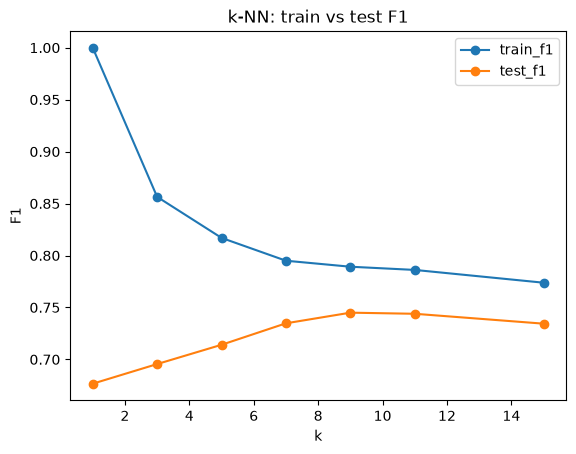

In [14]:
curve = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="cosine", algorithm="brute").fit(X_tr, y_tr)
    curve.append({"k": k,
                  "train_f1": f1_score(y_tr, knn.predict(X_tr), zero_division=0),
                  "test_f1": f1_score(y_te, knn.predict(X_te), zero_division=0)})
curve = pd.DataFrame(curve)
print(curve.round(3))
curve.plot(x="k", y=["train_f1", "test_f1"], marker="o", title="k-NN: train vs test F1")
plt.ylabel("F1"); plt.show()

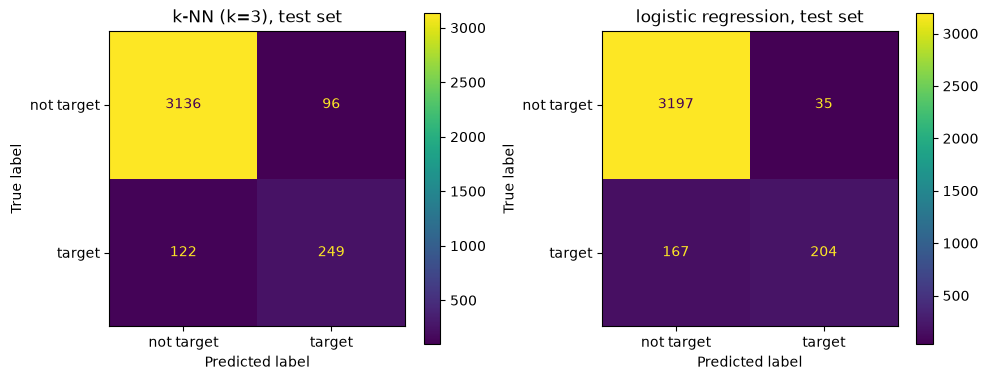

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

knn = KNeighborsClassifier(n_neighbors=3, metric="cosine", algorithm="brute").fit(X_tr, y_tr)
logreg = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, m) in zip(axes, [("k-NN (k=3)", knn), ("logistic regression", logreg)]):
    ConfusionMatrixDisplay.from_estimator(m, X_te, y_te, display_labels=["not target", "target"], ax=ax)
    ax.set_title(title + ", test set")
plt.tight_layout(); plt.show()

<div dir="rtl" align="right">

## Interpretation

**۱. Baseline و accuracy**
- مشاهده: baseline  accuracy برابر 0.897 دارد، ولی precision و recall و F1 آن برابر 0 است.
- دلیل: کلاس هدف (لیبل 3) فقط حدود 10.3٪ داده است و baseline همه را «غیرهدف» می‌گوید، پس در حدود 90٪ موارد «اتفاقی» درست می‌گوید.
- نتیجه: برای کلاس نادر accuracy گمراه‌کننده است. هر مدل باید با baseline و با precision و recall و F1 سنجیده شود، نه فقط accuracy.

**۲. مقایسهٔ مدل‌ها**
- مشاهده: بهترین F1 مربوط به k-NN با k=3 است (0.696) و بعد logistic regression (0.669) و درخت تصمیم (0.553). logistic regression بیشترین precision را دارد (0.854) ولی recall آن فقط 0.550 است.
- دلیل: متن با TF-IDF به یک بردار پراکندهٔ 5000 بعدی تبدیل می‌شود. در این فضا شباهت کسینوسی همسایه‌ها خوب کار می‌کند، ولی درخت با شرط‌های تک‌ویژگی‌ای نمی‌تواند الگوی کلمات را خوب بگیرد. logistic regression  در داده‌ای نامتوازن محتاط است و فقط موارد مطمئن را «هدف» می‌گوید.
پس K-NN انتخاب معقولانه تریست.

**۳. ویژگی جدید**
- مشاهده: بعد از افزودن ویژگی‌های دست‌ساز (n_words، n_chars، n_digits، n_percent، n_latin) F1 مدل k-NN از 0.696 به 0.638 رسید (تغییر 0.058-). برای درخت 0.003- و برای logistic regression 0.002- بود. مدل ساده‌ای که فقط از همین ویژگی‌ها استفاده کرد F1 برابر 0.016 داشت.
- دلیل: طول متن و تعداد عدد و حروف لاتین با موضوع مقاله ارتباط محکمی ندارند و اطلاعات موضوعی در خود کلمات است. در k-NN هم این ستون‌های اضافی با مقیاس تا 1، شباهت کسینوسی روی بردار TF-IDF را مخدوش کرده‌اند.
- نتیجه: این ویژگی‌های ساختاری (مثل طول متن و تعداد ارقام) هیچ اطلاعاتی درباره‌ی موضوع مقاله ندارند و باعث ایجاد نویز در مدل  می‌شوند. بنابراین فرضیه‌ی ما مبنی بر مفید بودن آن‌ها رد شد


**۴. بیش‌برازش**
- مشاهده: در k-NN با k=1 مقدار train_f1 برابر 1.0 و test_f1 برابر 0.677 است. با بزرگ شدن k مقدار train کم می‌شود و test تا k=9 بالا می‌رود (0.745) و بعد کمی افت می‌کند (0.734 در k=15). 
- دلیل: مدل پیچیده نمونه‌های آموزشی را حفظ می‌کند. در k=1 هر نمونه همسایهٔ خودش است، پس train_f1 بدیهی است.
- نتیجه: k=9 تعادل بهتری بین train و test دارد (فاصله حدود 0.04).

**۵. ماتریس درهم‌ریختگی**
- مشاهده: در مدل k-NN، مقدار FN برابر ۱۲۲ و FP برابر ۹۶ است (TP برابر ۲۴۹ و TN برابر ۳۱۳۶). در مقابل، مدل Logistic Regression دارای FP بسیار کمتری (۳۵) است اما FN بسیار بیشتری (۱۶۷) دارد .
- دلیل: هر دو مدل با مشکل کلاس نادر (حدود ۱۰٪) درگیر هستند، اما رفتارشان متفاوت است: k-NN با تکیه بر شباهت کلمات، مقالات هدف بیشتری را پیدا می‌کند (Recall بالاتر) اما مقالات غیرهدف بیشتری را هم اشتباهاً هدف اعلام می‌کند (FP بالاتر). در مقابل، Logistic Regression بسیار محتاط عمل می‌کند و فقط مواردی را هدف می‌گوید که مطمئن است؛ به همین دلیل FP آن پایین است اما مقالات هدف زیادی را از دست می‌دهد (FN بالا).
- نتیجه: انتخاب مدل به اولویت ما بستگی دارد. اگر سیستم پیشنهاددهنده باشد و از دست دادن یک مقاله‌ی مرتبط (FN) فاجعه باشد، k-NN انتخاب بهتری است (چون Recall بالاتری دارد). اما اگر هدف فیلتر کردن دقیق باشد و پیشنهاد اشتباه آزاردهنده باشد، Logistic Regression با FP پایین‌ترش منطقی‌تر است.

</div>